In [1]:
# Load environment variables and set up auto-reload
from dotenv import load_dotenv
load_dotenv()

%load_ext autoreload
%autoreload 2

# Research Supervisor

*The supervisor has a simple job: delegate research tasks to an appropriate number of sub-agents.*

Here is our overall research flow:

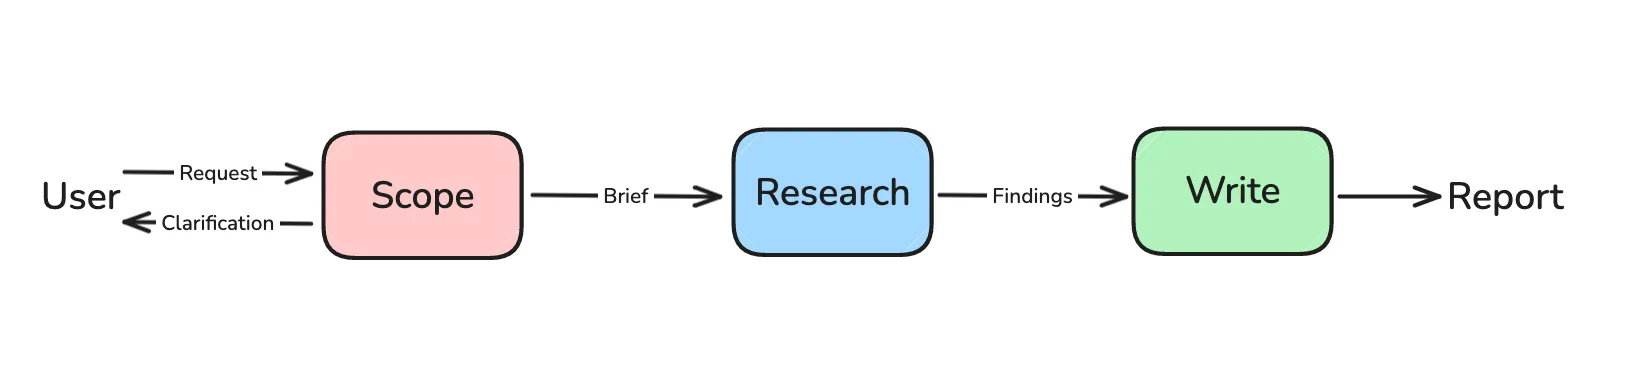

We previously built a research agent bound to either custom tools or MCP server. Now, what happens if the request is complex and has several sub-topics? Single agent response quality *can* suffer with multiple sub-topics (e.g., compare A to B to C) because a single context window needs to store and reason about tool feedback across all of the sub-topics. 

[Numerous failure modes](https://www.dbreunig.com/2025/06/22/how-contexts-fail-and-how-to-fix-them.html), such as [context clash](https://www.dbreunig.com/2025/06/22/how-contexts-fail-and-how-to-fix-them.html), become prevalent as the context window accumulates tool calls across many different sub-topics. As discussed in [Anthropic's blog post](https://www.anthropic.com/engineering/built-multi-agent-research-system), multi-agent systems can split sub-topic to sub-agents with isolated context windows. We'll build a system where a supervisor determines if the research brief can be broken-down into independent sub-topics and delegates to sub-agents with isolated context windows. 

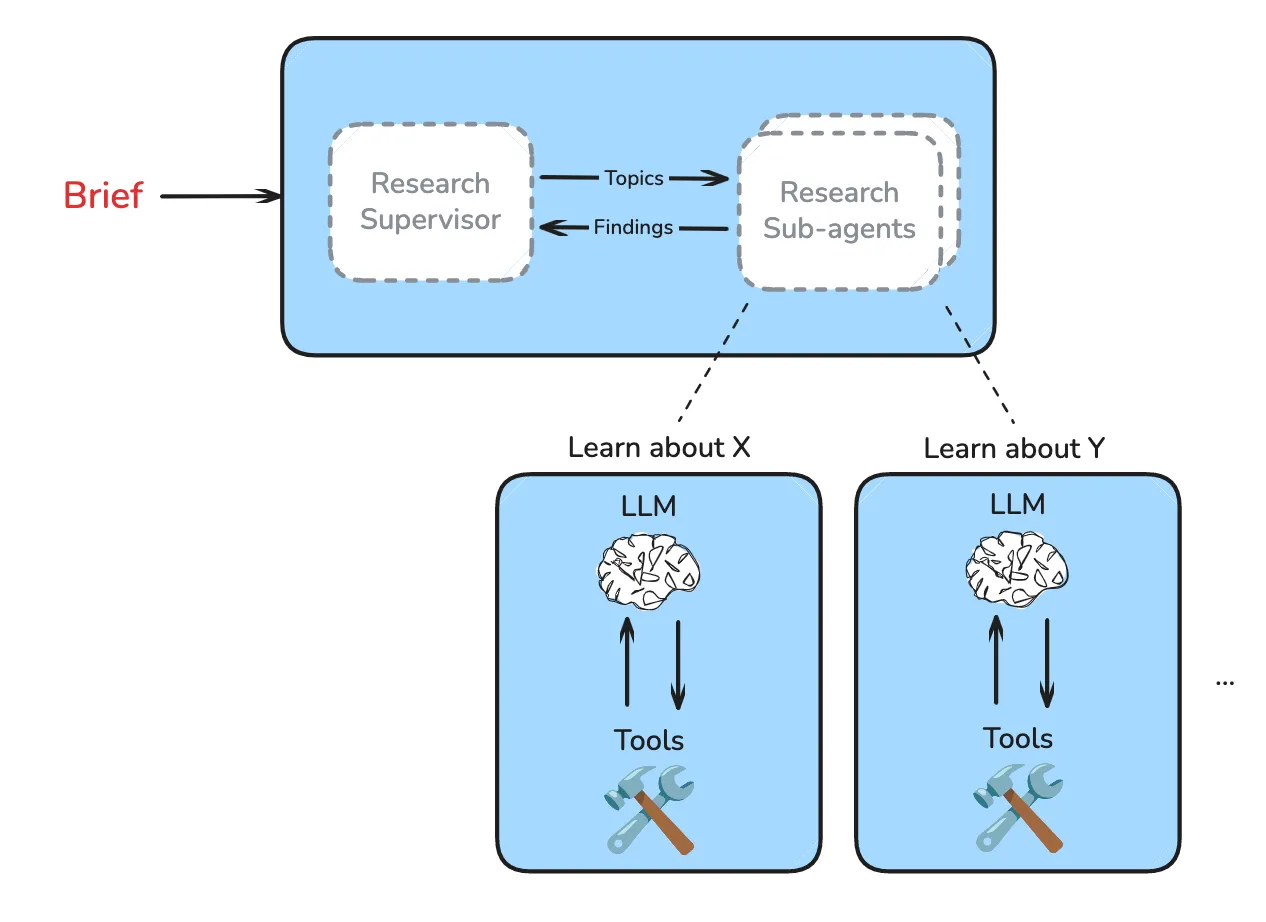

### Prompt

Now, let's design a prompt for the supervisor that follows the principles we've discussed, and include some insights from [the research literature](https://www.anthropic.com/engineering/built-multi-agent-research-system).

#### 1. Think Like The Agent
What instructions would you give a new work colleague?
- **Read the question carefully** - What specific information does the user need?
- **Decide how to delegate the research** - Carefully consider the question and decide how to delegate the research. Are there multiple independent directions that can be explored simultaneously?
- **After each call to ConductResearch, pause and assess** - Do I have enough to answer? What's still missing?

#### 2. Concrete Heuristics (For task delegation)
Use **Hard Limits** to prevent the research agent from calling tools excessively:
- **Bias towards single agent** - Use single agent for simplicity unless the user request has clear opportunity for parallelization. 
- **Stop when you can answer confidently** - Don't keep delegating research for perfection.
- **Limit tool calls** - Always stop after 3 tool calls to ConductResearch if you cannot find the right source(s).

#### 3. Show your thinking
Before you call ConductResearch tool call, use think_tool to plan your approach:
- Can the task be broken down into smaller sub-tasks?

After each ConductResearch tool call, use think_tool to analyze the results:
- What key information did I find? 
- What's missing?
- Do I have enough to answer the question comprehensively?
- Should I search more or provide my answer?

#### 4. Scaling rules
Simple fact-finding, lists, and rankings can use a single sub-agent.
- *Example*: List the top 10 coffee shops in San Francisco -> Use 1 sub-agent

Comparisons presented in the user request can use a sub-agent for each element of the comparison.
- *Example*: Compare OpenAI vs. Anthropic vs. DeepMind approaches to AI safety -> Use 3 sub-agents.
- Delegate clear, distinct, non-overlapping subtopics

In [2]:
from utils import show_prompt
from deep_research_from_scratch.prompts import lead_researcher_prompt
show_prompt(lead_researcher_prompt, "Lead Researcher Prompt")

╭──────────────────────────────────────────── Lead Researcher Prompt ─────────────────────────────────────────────╮
│                                                                                                                 │
│  You are a research supervisor. Your job is to conduct research by calling the "ConductResearch" tool. For      │
│  context, today's date is {date}.                                                                               │
│                                                                                                                 │
│  <Task>                                                                                                         │
│  Your focus is to call the "ConductResearch" tool to conduct research against the overall research question     │
│  passed in by the user.                                                                                         │
│  When you are completely satisfied with the research findings returned from the tool calls, then you should     │
│  call the "ResearchComplete" tool to indicate that you are done with your research.                             │
│  </Task>                                                                                                        │
│                                                                                                                 │
│  <Available Tools>                                                                                              │
│  You have access to three main tools:                                                                           │
│  1. **ConductResearch**: Delegate research tasks to specialized sub-agents                                      │
│  2. **ResearchComplete**: Indicate that research is complete                                                    │
│  3. **think_tool**: For reflection and strategic planning during research                                       │
│                                                                                                                 │
│  **CRITICAL: Use think_tool before calling ConductResearch to plan your approach, and after each                │
│  ConductResearch to assess progress**                                                                           │
│  **PARALLEL RESEARCH**: When you identify multiple independent sub-topics that can be explored simultaneously,  │
│  make multiple ConductResearch tool calls in a single response to enable parallel research execution. This is   │
│  more efficient than sequential research for comparative or multi-faceted questions. Use at most                │
│  {max_concurrent_research_units} parallel agents per iteration.                                                 │
│  </Available Tools>                                                                                             │
│                                                                                                                 │
│  <Instructions>                                                                                                 │
│  Think like a research manager with limited time and resources. Follow these steps:                             │
│                                                                                                                 │
│  1. **Read the question carefully** - What specific information does the user need?                             │
│  2. **Decide how to delegate the research** - Carefully consider the question and decide how to delegate the    │
│  research. Are there multiple independent directions that can be explored simultaneously?                       │
│  3. **After each call to ConductResearch, pause and assess** - Do I have enough to answer? What's still         │
│  missing?                                                                                                       │
│  </Instructions>                                      

### State

The supervisor state manages the overall research coordination, while the researcher state handles individual research tasks.

In [3]:
%%writefile ../src/deep_research_from_scratch/state_multi_agent_supervisor.py

"""
State Definitions for Multi-Agent Research Supervisor

This module defines the state objects and tools used for the multi-agent
research supervisor workflow, including coordination state and research tools.
"""

import operator
from typing_extensions import Annotated, TypedDict, Sequence

from langchain_core.messages import BaseMessage
from langchain_core.tools import tool
from langgraph.graph.message import add_messages
from pydantic import BaseModel, Field

class SupervisorState(TypedDict):
    """
    State for the multi-agent research supervisor.
    
    Manages coordination between supervisor and research agents, tracking
    research progress and accumulating findings from multiple sub-agents.
    """
    
    # Messages exchanged with supervisor for coordination and decision-making
    supervisor_messages: Annotated[Sequence[BaseMessage], add_messages]
    # Detailed research brief that guides the overall research direction
    research_brief: str
    # Processed and structured notes ready for final report generation
    notes: Annotated[list[str], operator.add] = []
    # Counter tracking the number of research iterations performed
    research_iterations: int = 0
    # Raw unprocessed research notes collected from sub-agent research
    raw_notes: Annotated[list[str], operator.add] = []

@tool
class ConductResearch(BaseModel):
    """Tool for delegating a research task to a specialized sub-agent."""
    research_topic: str = Field(
        description="The topic to research. Should be a single topic, and should be described in high detail (at least a paragraph).",
    )

@tool
class ResearchComplete(BaseModel):
    """Tool for indicating that the research process is complete."""
    pass

Overwriting ../src/deep_research_from_scratch/state_multi_agent_supervisor.py


### Multi-agent 

Now, we'll define our agent. A multi-agent system is a system that consists of multiple agents that work together to complete a task. The main benefit is context isolated, as discussed in [Context Engineering for Agents](https://blog.langchain.com/context-engineering-for-agents/). 

**Note:** The default settings here are for up to 3 research agents to run concurrently each with up to 6 calls to perform research.  This can take several minutes to run and depending on the users Tier, a 429 HTTP error (rate limit exceeded) *may* occur.  This may be avoided by raising the users's Tier to gain a better rate limit.  

Other less high thinking models may decide to run only a single research agent and perhaps avoid the rate limit error.  The point of this exercise, however, is to illustrate how concurrency of research agents may be achieved.


In [4]:
%%writefile ../src/deep_research_from_scratch/multi_agent_supervisor.py

"""Multi-agent supervisor for coordinating research across multiple specialized agents.

This module implements a supervisor pattern where:
1. A supervisor agent coordinates research activities and delegates tasks
2. Multiple researcher agents work on specific sub-topics independently
3. Results are aggregated and compressed for final reporting

The supervisor uses parallel research execution to improve efficiency while
maintaining isolated context windows for each research topic.
"""

import asyncio

from typing_extensions import Literal

from langchain.chat_models import init_chat_model
from langchain_core.messages import (
    HumanMessage, 
    BaseMessage, 
    SystemMessage, 
    ToolMessage,
    filter_messages
)
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command

from deep_research_from_scratch.prompts import lead_researcher_prompt
from deep_research_from_scratch.research_agent import researcher_agent
from deep_research_from_scratch.state_multi_agent_supervisor import (
    SupervisorState, 
    ConductResearch, 
    ResearchComplete
)
from deep_research_from_scratch.utils import get_today_str, think_tool

def get_notes_from_tool_calls(messages: list[BaseMessage]) -> list[str]:
    """Extract research notes from ToolMessage objects in supervisor message history.
    
    This function retrieves the compressed research findings that sub-agents
    return as ToolMessage content. When the supervisor delegates research to
    sub-agents via ConductResearch tool calls, each sub-agent returns its
    compressed findings as the content of a ToolMessage. This function
    extracts all such ToolMessage content to compile the final research notes.
    
    Args:
        messages: List of messages from supervisor's conversation history
        
    Returns:
        List of research note strings extracted from ToolMessage objects
    """
    return [tool_msg.content for tool_msg in filter_messages(messages, include_types="tool")]

# Ensure async compatibility for Jupyter environments
try:
    import nest_asyncio
    # Only apply if running in Jupyter/IPython environment
    try:
        from IPython import get_ipython
        if get_ipython() is not None:
            nest_asyncio.apply()
    except ImportError:
        pass  # Not in Jupyter, no need for nest_asyncio
except ImportError:
    pass  # nest_asyncio not available, proceed without it


# ===== CONFIGURATION =====

supervisor_tools = [ConductResearch, ResearchComplete, think_tool]
supervisor_model = init_chat_model(model="anthropic:claude-sonnet-4-6")
supervisor_model_with_tools = supervisor_model.bind_tools(supervisor_tools)

# System constants
# Maximum number of tool call iterations for individual researcher agents
# This prevents infinite loops and controls research depth per topic
max_researcher_iterations = 6 # Calls to think_tool + ConductResearch

# Maximum number of concurrent research agents the supervisor can launch
# This is passed to the lead_researcher_prompt to limit parallel research tasks
max_concurrent_researchers = 3

# ===== SUPERVISOR NODES =====

async def supervisor(state: SupervisorState) -> Command[Literal["supervisor_tools"]]:
    """Coordinate research activities.
    
    Analyzes the research brief and current progress to decide:
    - What research topics need investigation
    - Whether to conduct parallel research
    - When research is complete
    
    Args:
        state: Current supervisor state with messages and research progress
        
    Returns:
        Command to proceed to supervisor_tools node with updated state
    """
    supervisor_messages = state.get("supervisor_messages", [])
    
    # Prepare system message with current date and constraints
    system_message = lead_researcher_prompt.format(
        date=get_today_str(), 
        max_concurrent_research_units=max_concurrent_researchers,
        max_researcher_iterations=max_researcher_iterations
    )
    messages = [SystemMessage(content=system_message)] + supervisor_messages
    
    # Make decision about next research steps
    response = await supervisor_model_with_tools.ainvoke(messages)
    
    return Command(
        goto="supervisor_tools",
        update={
            "supervisor_messages": [response],
            "research_iterations": state.get("research_iterations", 0) + 1
        }
    )

async def supervisor_tools(state: SupervisorState) -> Command[Literal["supervisor", "__end__"]]:
    """Execute supervisor decisions - either conduct research or end the process.
    
    Handles:
    - Executing think_tool calls for strategic reflection
    - Launching parallel research agents for different topics
    - Aggregating research results
    - Determining when research is complete
    
    Args:
        state: Current supervisor state with messages and iteration count
        
    Returns:
        Command to continue supervision, end process, or handle errors
    """
    supervisor_messages = state.get("supervisor_messages", [])
    research_iterations = state.get("research_iterations", 0)
    most_recent_message = supervisor_messages[-1]
    
    # Initialize variables for single return pattern
    tool_messages = []
    all_raw_notes = []
    next_step = "supervisor"  # Default next step
    should_end = False
    
    # Check exit criteria first
    exceeded_iterations = research_iterations >= max_researcher_iterations
    no_tool_calls = not most_recent_message.tool_calls
    research_complete = any(
        tool_call["name"] == "ResearchComplete" 
        for tool_call in most_recent_message.tool_calls
    )
    
    if exceeded_iterations or no_tool_calls or research_complete:
        should_end = True
        next_step = END
    
    else:
        # Execute ALL tool calls before deciding next step
        try:
            # Separate think_tool calls from ConductResearch calls
            think_tool_calls = [
                tool_call for tool_call in most_recent_message.tool_calls 
                if tool_call["name"] == "think_tool"
            ]
            
            conduct_research_calls = [
                tool_call for tool_call in most_recent_message.tool_calls 
                if tool_call["name"] == "ConductResearch"
            ]

            # Handle think_tool calls (synchronous)
            for tool_call in think_tool_calls:
                observation = think_tool.invoke(tool_call["args"])
                tool_messages.append(
                    ToolMessage(
                        content=observation,
                        name=tool_call["name"],
                        tool_call_id=tool_call["id"]
                    )
                )

            # Handle ConductResearch calls (asynchronous)
            if conduct_research_calls:
                # Launch parallel research agents
                coros = [
                    researcher_agent.ainvoke({
                        "researcher_messages": [
                            HumanMessage(content=tool_call["args"]["research_topic"])
                        ],
                        "research_topic": tool_call["args"]["research_topic"]
                    }) 
                    for tool_call in conduct_research_calls
                ]

                # Wait for all research to complete
                tool_results = await asyncio.gather(*coros)

                # Format research results as tool messages
                # Each sub-agent returns compressed research findings in result["compressed_research"]
                # We write this compressed research as the content of a ToolMessage, which allows
                # the supervisor to later retrieve these findings via get_notes_from_tool_calls()
                research_tool_messages = [
                    ToolMessage(
                        content=result.get("compressed_research", "Error synthesizing research report"),
                        name=tool_call["name"],
                        tool_call_id=tool_call["id"]
                    ) for result, tool_call in zip(tool_results, conduct_research_calls)
                ]
                
                tool_messages.extend(research_tool_messages)

                # Aggregate raw notes from all research
                all_raw_notes = [
                    "\n".join(result.get("raw_notes", [])) 
                    for result in tool_results
                ]
                
        except Exception as e:
            print(f"Error in supervisor tools: {e}")
            should_end = True
            next_step = END
    
    # Single return point with appropriate state updates
    if should_end:
        return Command(
            goto=next_step,
            update={
                "notes": get_notes_from_tool_calls(supervisor_messages),
                "research_brief": state.get("research_brief", "")
            }
        )
    else:
        return Command(
            goto=next_step,
            update={
                "supervisor_messages": tool_messages,
                "raw_notes": all_raw_notes
            }
        )

# ===== GRAPH CONSTRUCTION =====

# Build supervisor graph
supervisor_builder = StateGraph(SupervisorState)
supervisor_builder.add_node("supervisor", supervisor)
supervisor_builder.add_node("supervisor_tools", supervisor_tools)
supervisor_builder.add_edge(START, "supervisor")
supervisor_agent = supervisor_builder.compile()

Overwriting ../src/deep_research_from_scratch/multi_agent_supervisor.py


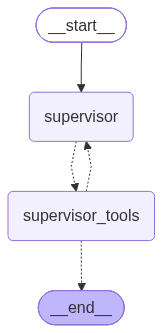

In [5]:
from IPython.display import Image, display
from deep_research_from_scratch.multi_agent_supervisor import supervisor_agent

# Show the agent
display(Image(supervisor_agent.get_graph(xray=True).draw_mermaid_png()))

In [6]:
# Run the multi-agent supervisor agent
from utils import format_messages
from langchain_core.messages import HumanMessage

research_brief = """I want to identify and evaluate the coffee shops in San Francisco that are considered the best based specifically  
on coffee quality. My research should focus on analyzing and comparing coffee shops within the San Francisco area, 
using coffee quality as the primary criterion. I am open regarding methods of assessing coffee quality (e.g.,      
expert reviews, customer ratings, specialty coffee certifications), and there are no constraints on ambiance,      
location, wifi, or food options unless they directly impact perceived coffee quality. Please prioritize primary    
sources such as the official websites of coffee shops, reputable third-party coffee review organizations (like     
Coffee Review or Specialty Coffee Association), and prominent review aggregators like Google or Yelp where direct  
customer feedback about coffee quality can be found. The study should result in a well-supported list or ranking of
the top coffee shops in San Francisco, emphasizing their coffee quality according to the latest available data as  
of July 2025."""

result = await supervisor_agent.ainvoke({"supervisor_messages": [HumanMessage(content=f"{research_brief}.")]})
format_messages(result['supervisor_messages'])

╭─────────────────────────────────────────────────── 🧑 Human ────────────────────────────────────────────────────╮
│ I want to identify and evaluate the coffee shops in San Francisco that are considered the best based            │
│ specifically                                                                                                    │
│ on coffee quality. My research should focus on analyzing and comparing coffee shops within the San Francisco    │
│ area,                                                                                                           │
│ using coffee quality as the primary criterion. I am open regarding methods of assessing coffee quality (e.g.,   │
│ expert reviews, customer ratings, specialty coffee certifications), and there are no constraints on ambiance,   │
│ location, wifi, or food options unless they directly impact perceived coffee quality. Please prioritize primary │
│ sources such as the official websites of coffee shops, reputable third-party coffee review organizations (like  │
│ Coffee Review or Specialty Coffee Association), and prominent review aggregators like Google or Yelp where      │
│ direct                                                                                                          │
│ customer feedback about coffee quality can be found. The study should result in a well-supported list or        │
│ ranking of                                                                                                      │
│ the top coffee shops in San Francisco, emphasizing their coffee quality according to the latest available data  │
│ as                                                                                                              │
│ of July 2025..                                                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│ 🔧 Tool Call: think_tool                                                                                        │
│    Args: {                                                                                                      │
│   "reflection": "The user wants a well-researched ranking of the best coffee shops in San Francisco based       │
│ specifically on coffee quality. They want:\n1. Primary sources: coffee shop official websites, Coffee Review,   │
│ Specialty Coffee Association, Google/Yelp ratings\n2. Focus on coffee quality metrics: expert reviews, customer │
│ ratings, specialty certifications\n3. Latest data as of July 2025\n\nThis is a multi-faceted research task. I   │
│ can break it into parallel research streams:\n1. Expert reviews and specialty coffee certifications (Coffee     │
│ Review, SCA, barista championships, etc.)\n2. Customer ratings and review aggregators (Google, Yelp) focused on │
│ coffee quality in SF\n3. Top-ranked SF coffee shops from reputable coffee-focused publications and blogs (Eater │
│ SF, SF Chronicle, Bon App\u00e9tit, etc.)\n\nThese three angles are independent and can be researched           │
│ simultaneously. Let me deploy 3 parallel agents."                                                               │
│ }                                                                                                               │
│    ID: toolu_01AUwY6VVfaJo2h9aC5rHn7w                                                                           │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Reflection recorded: The user wants a well-researched ranking of the best coffee shops in San Francisco based   │
│ specifically on coffee quality. They want:                                                                      │
│ 1. Primary sources: coffee shop official websites, Coffee Review, Specialty Coffee Association, Google/Yelp     │
│ ratings                                                                                                         │
│ 2. Focus on coffee quality metrics: expert reviews, customer ratings, specialty certifications                  │
│ 3. Latest data as of July 2025                                                                                  │
│                                                                                                                 │
│ This is a multi-faceted research task. I can break it into parallel research streams:                           │
│ 1. Expert reviews and specialty coffee certifications (Coffee Review, SCA, barista championships, etc.)         │
│ 2. Customer ratings and review aggregators (Google, Yelp) focused on coffee quality in SF                       │
│ 3. Top-ranked SF coffee shops from reputable coffee-focused publications and blogs (Eater SF, SF Chronicle, Bon │
│ Appétit, etc.)                                                                                                  │
│                                                                                                                 │
│ These three angles are independent and can be researched simultaneously. Let me deploy 3 parallel agents.       │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│ I'll break this into three parallel research streams to cover expert certifications, customer ratings, and      │
│ editorial rankings simultaneously.                                                                              │
│                                                                                                                 │
│ 🔧 Tool Call: ConductResearch                                                                                   │
│    Args: {                                                                                                      │
│   "research_topic": "Research the best coffee shops in San Francisco based on expert coffee quality             │
│ assessments, specialty coffee certifications, and professional reviews as of 2024-2025. Focus on: (1) Coffee    │
│ Review scores and reviews for San Francisco coffee shops, (2) Specialty Coffee Association recognition or       │
│ certifications for San Francisco roasters and cafes, (3) any barista championship connections or                │
│ competition-level coffee served in San Francisco cafes, (4) expert coffee critic write-ups from sources like    │
│ Sprudge, Perfect Daily Grind, or similar specialty coffee publications. For each coffee shop mentioned, note    │
│ the specific coffee quality attributes highlighted (e.g., sourcing, roasting quality, brewing technique,        │
│ espresso quality). Please include URLs or source names where possible."                                         │
│ }                                                                                                               │
│    ID: toolu_01TxK5vjTQSEmShyJum9qui7                                                                           │
│                                                                                                                 │
│ 🔧 Tool Call: ConductResearch                                                                                   │
│    Args: {                                                                                                      │
│   "research_topic": "Research the best coffee shops in San Francisco as ranked by customer reviews on Google    │
│ Maps and Yelp, specifically filtering for coffee quality as of 2024-2025. Find coffee shops in San Francisco    │
│ with the highest ratings (4.5 stars and above) where customer reviews specifically praise the quality of the    │
│ coffee itself \u2014 not just ambiance or food. Look for patterns in reviews mentioning: espresso quality,      │
│ latte art, pour-over quality, single-origin offerings, freshness of beans, brewing skill of baristas. Identify  │
│ the top 10-15 San Francisco coffee shops by coffee quality according to aggregated customer feedback. Include   │
│ shop names, neighborhoods, approximate ratings, and specific coffee quality attributes customers highlight."    │
│ }                                                                                                               │
│    ID: toolu_01ASRkTgaH49YCQogXtnV1zm                                                                           │
│                                                                                                                 │
│ 🔧 Tool Call: ConductResearch                                                                                   │
│    Args: {                                                                                                      │
│   "research_topic": "Research editorial and publication rankings of the best coffee shops in San Francisco      │
│ specifically for coffee quality, published between 2023 and July 2025. Sources to search include: Eater San     │
│ Francisco, San Francisco Chronicle, Bon App\u00e9tit, Food and Wine, Conde Nast Traveler, Timeout San           │
│ Francisco, San Francisco Magazine, and any other reputable

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ **List of Queries and Tool Calls Made**                                                                         │
│                                                                                                                 │
│ 1. "best coffee shops San Francisco 2024 2025 specialty coffee expert reviews"                                  │
│ 2. "Coffee Review scores San Francisco coffee shops 2024"                                                       │
│ 3. "Sprudge San Francisco coffee shops 2024 2025 best specialty coffee"                                         │
│ 4. "Sprudge San Francisco coffee Sightglass Ritual Equator Four Barrel specialty review"                        │
│ 5. "San Francisco barista championship competition coffee cafe 2024 2025 US Barista Championship"               │
│ 6. "Coffee Review 90+ score San Francisco roasters Equator Sightglass Linea Ritual 2024"                        │
│ 7. "Linea Caffe Saint Frank Ritual Andytown San Francisco specialty coffee expert review Sprudge Perfect Daily  │
│ Grind"                                                                                                          │
│ 8. "Equator Coffees SCA certification B Corp San Francisco Sightglass Ritual barista competition championship"  │
│ 9. "Linea Caffe San Francisco Charles Babinski barista championship espresso quality review"                    │
│ 10. "Wrecking Ball Coffee Roasters San Francisco specialty review Andytown Pinhole Grand Coffee expert quality  │
│ 2024"                                                                                                           │
│                                                                                                                 │
│ ---                                                                                                             │
│                                                                                                                 │
│ **Fully Comprehensive Findings**                                                                                │
│                                                                                                                 │
│ San Francisco is highlighted as a historic and dynamic center of coffee culture. San Francisco is and has been  │
│ for many the world over the summit of coffee culture; it's where Trish Rothgeb introduced the 'waves of coffee' │
│ terminology and changed the industry forever, where the Irish Coffee was born, where many claim Italian         │
│ espresso culture hit the United States, and where vacuum-sealed coffee was invented. These 17 coffee shops keep │
│ the torch burning, making those great ascents into the future. Paolo Bicchieri thinks a good coffee shop should │
│ offer well-sourced beans, lively conversation, and a respite from the world. Saint Frank is to San Francisco    │
│ coffee as Dungeness crab is to San Francisco restaurants: when the time is right in the city, nothing else will │
│ do [1].                                                                                                         │
│                                                                                                                 │
│ Eater SF's best coffee shops guide profiles 17 standout coffee shops presently shaping the city's specialty     │
│ coffee scene, including Saint Frank Coffee, Caffe Trieste, Capital One Cafe, Cafe Shoji, The Scullery, Paper    │
│ Son, Hi NRG, Delah Coffee House, Golden Goat Coffee, Linea Coffee Roasting + Caffe, Hedge Coffee Roasters, The  │
│ Coffee Movement at Side A, Grand Coffee, Pinhole Coffee, Hey Neighbor Cafe, Excelsior Coffee, and Better Half   │
│ Coffee. Each entry includes location details and highlights unique attributes such as specialty drinks,         │
│ influential owners, and community roles [1].           

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ **List of Queries and Tool Calls Made**                                                                         │
│                                                                                                                 │
│ 1. best coffee shops San Francisco 2024 2025 highest rated Google Maps Yelp coffee quality reviews              │
│ 2. San Francisco top rated coffee shops espresso quality pour over single origin 4.5 stars 2024                 │
│ 3. Linea Caffe Saint Frank Ritual Coffee San Francisco Yelp Google reviews espresso quality rating 2024 2025    │
│ 4. San Francisco best specialty coffee 2024 customer reviews espresso latte art pour over barista skill single  │
│ origin beans                                                                                                    │
│ 5. Wrecking Ball Coffee Sightglass Ritual Andytown San Francisco Yelp rating stars reviews coffee quality 2024  │
│ 6. Paper Son Coffee Golden Goat Linea Caffe Verve Sextant San Francisco Google Maps rating reviews barista      │
│ espresso pour over 2024 2025                                                                                    │
│ 7. San Francisco coffee shop Yelp 4.5 5 stars reviews "espresso" OR "pour over" OR "latte art" OR "single       │
│ origin" OR "freshly roasted" 2024 2025 top rated                                                                │
│                                                                                                                 │
│ ---                                                                                                             │
│                                                                                                                 │
│ **Fully Comprehensive Findings**                                                                                │
│                                                                                                                 │
│ ---                                                                                                             │
│                                                                                                                 │
│ **From Tasting Table:**                                                                                         │
│ - List included Compton's Coffee House, Red Bay Coffee, Ritual, Mazarine, Blue Bottle Coffee, Sightglass        │
│ Coffee, Wrecking Ball Coffee Roasters, Equator Coffee, The Scullery, Sextant Coffee Roasters, Hey Neighbor      │
│ Cafe, Java on Ocean, Philz Coffee, Saint Frank Coffee, Flywheel Coffee Roasters, Andytown Coffee.               │
│ - Ritual: “Ensures customers drink specialty-grade coffees sourced by smaller farmers”.                         │
│ - Mazarine: “King of the pour-over coffee with selections varying daily”.                                       │
│ - Red Bay Coffee: “Focuses on specialty coffees that are sustainably sourced and diversifies the coffee         │
│ production community”.                                                                                          │
│ - Compton's Coffee House: “The Lavender Latte at this cute spot is one of the best in the city”.                │
│ - Philz Coffee: “Blends are as unique as they are tasty, with a wide variety of flavors to choose from on the   │
│ menu” [1].                                                                                                      │
│                                                                                                                 │
│ ---                                                                                                             │
│                                                                                                                 │
│ **From The Infatuation:**                              

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ **List of Queries and Tool Calls Made**                                                                         │
│                                                                                                                 │
│ - Searched for "best coffee shops San Francisco 2024 2025 Eater SF Chronicle rankings" [1][2][3]                │
│ - Searched for "best coffee San Francisco Bon Appetit Food Wine Conde Nast Traveler 2023 2024 2025" [4][5][6]   │
│ - Searched for "San Francisco coffee shops awards Good Food Awards Roaster of the Year 2023 2024 2025"          │
│ [7][8][9]                                                                                                       │
│ - Searched for "San Francisco Chronicle best coffee 2023 2024 2025 ranked cafes" [10][11][12]                   │
│ - Searched for "Timeout San Francisco best coffee shops 2023 2024 2025" [13][14][15]                            │
│ - Searched for "Linea Caffe Good Food Award 2024 winner coffee San Francisco" [16][17][18]                      │
│ - Searched for "Food Wine magazine best coffee San Francisco 2023 2024 2025 cafe ranked" [19][20][21]           │
│ - Searched for "Wrecking Ball Ritual Sightglass Andytown Good Food Awards Roaster Year 2023 2024 2025 San       │
│ Francisco" [22][23][24]                                                                                         │
│ - Searched for "Linea Caffe Good Food Award winning coffee origin 2024 San Francisco Mission District"          │
│ [25][26][27]                                                                                                    │
│ - Searched for "San Francisco coffee \"Food and Wine\" OR \"San Francisco Magazine\" OR \"Bon Appetit\" best    │
│ cafe 2023 2024 2025 Sightglass Ritual Andytown" [28][29][30]                                                    │
│ - Searched for "Good Food Awards 2023 2025 coffee winners San Francisco Bay Area roasters" [31][32][33]         │
│ - Searched for "\"best coffee\" \"San Francisco\" site:bonappetit.com OR site:foodandwine.com 2023 2024 2025"   │
│ [34][35][36]                                                                                                    │
│                                                                                                                 │
│ ---                                                                                                             │
│                                                                                                                 │
│ **Fully Comprehensive Findings**                                                                                │
│                                                                                                                 │
│ **Best Coffee Shops in San Francisco (2025) by Globey on Postcard**                                             │
│                                                                                                                 │
│ - The Coffee Movement: A tiny bar with big standards, known for coffee flights and a measured, two-step service │
│ that slows you down in the best way. Frequently praised by the San Francisco Chronicle and local coffee geeks   │
│ for precision and hospitality.                                                                                  │
│ - Saint Frank Coffee.                                                                                           │
│ - Andytown Coffee Roasters.                                                                                     │
│ - Pinhole Coffee: Rotating single origins and a custom Linea house blend anchor drinks that the San Francisco   │
│ Chronicle and neighborhood regulars praise for personality and care.                                            │
│ - Sextant Coffee Roasters.                             

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│ 🔧 Tool Call: think_tool                                                                                        │
│    Args: {                                                                                                      │
│   "reflection": "I now have extremely comprehensive research from three parallel agents covering:\n\n1.         │
│ **Expert/specialty coffee assessments**: Coffee Review scores for SF roasters, SCA certifications, barista      │
│ championship connections, Sprudge coverage, detailed tasting notes for Equator, Sightglass, Linea, Ritual,      │
│ Wrecking Ball, Andytown, Sextant, Flywheel, etc.\n\n2. **Customer ratings/review aggregators**: Google/Yelp     │
│ data for Saint Frank, Andytown, Linea, Sightglass, Wrecking Ball, Paper Son, The Coffee Movement, Pinhole       │
│ Coffee, etc. with specific coffee quality attributes highlighted by customers.\n\n3. **Editorial/publication    │
│ rankings**: Eater SF, SF Chronicle, Timeout, The Infatuation, Bon App\u00e9tit, Food & Wine, Barista Magazine,  │
│ Cond\u00e9 Nast Traveler coverage, plus Good Food Awards (Linea Caffe won 2024), B Corp certifications          │
│ (Equator, Linea), etc.\n\nKey findings that allow me to create a well-supported, ranked list:\n\n**Top Tier     │
│ (appearing across ALL research streams with the strongest quality signals):**\n\n1. **Linea Caffe** -           │
│ Universally praised: NY Times Wirecutter \"most elegant and balanced cup of coffee I've ever had,\" Food &      │
│ Wine's best independent coffee shops nationally, 2024 Good Food Award winner (Organic Bire Forest, Ethiopia     │
│ Guji), B Corp certified 2023, SF's first fully organic-certified roaster, expert Andrew Barnett with 40+ years  │
│ experience. \u2b50 Arguably the top pick for pure coffee quality.\n\n2. **Ritual Coffee Roasters** - Founded    │
│ 2005, pioneer of SF specialty coffee, direct trade, single-origin, seasonal rotating menu, recently opened      │
│ Financial District location inspired by Italian coffee bars, V60 pour-over bar, Sprudge featured. The           │
│ \"godfather\" of SF's specialty coffee movement.\n\n3. **Wrecking Ball Coffee Roasters** - Founded by Trish     │
│ Rothgeb (coined \"third wave coffee\"), Cond\u00e9 Nast Traveler praised, Pillow Fight espresso blend           │
│ well-known, Q-Grader certified founder, consistently recognized.\n\n4. **Sightglass Coffee** - USDA Certified   │
│ Organic, small-batch roasting, vintage Probat machines, Coffee Review reviewed (Owl's Howl), Bon App\u00e9tit   │
│ featured, educational lab. 4.5 stars on Bean Box from 25 reviews.\n\n5. **Equator Coffees** - First B Corp      │
│ coffee roaster in California (2011), B Impact score 90.4, direct trade since inception, Coffee Review reviewed  │
│ (Kenya Mount Kirinyaga), Timeout SF noted French Laundry Blend served at Thomas Keller's restaurant. 30+ years  │
│ of quality.\n\n6. **Saint Frank Coffee** - Bolivian-sourced espresso, floral/delicate flavors, 4.5\u2605 Google │
│ rating, Eater SF \"as essential as Dungeness crab to SF,\" SF Chronicle featured, almond macadamia milk.        │
│ Described as the best espresso shop in the city by multiple sources.\n\n7. **Andytown Coffee Roasters** -       │
│ 4.6\u2605 Google (highest rated among top tier), famous Snowy Plover, Brown Sugar Latte, 10 locations while     │
│ maintaining quality per Barista Magazine, woman-owned.\n\n8. **The Coffee Movement** - SF Chronicle top pick,   │
│ multi-roaster rotating weekly, coffee flights/tasting options, two-step ordering process for precision, Eater   │
│ SF best espresso list.\n\n9. **Paper Son Coffee** - \"Best Coffee in the Bay Area\" per SF Chronicle, Asian     │
│ American heritage, espresso passionfruit tonic praised b

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Reflection recorded: I now have extremely comprehensive research from three parallel agents covering:           │
│                                                                                                                 │
│ 1. **Expert/specialty coffee assessments**: Coffee Review scores for SF roasters, SCA certifications, barista   │
│ championship connections, Sprudge coverage, detailed tasting notes for Equator, Sightglass, Linea, Ritual,      │
│ Wrecking Ball, Andytown, Sextant, Flywheel, etc.                                                                │
│                                                                                                                 │
│ 2. **Customer ratings/review aggregators**: Google/Yelp data for Saint Frank, Andytown, Linea, Sightglass,      │
│ Wrecking Ball, Paper Son, The Coffee Movement, Pinhole Coffee, etc. with specific coffee quality attributes     │
│ highlighted by customers.                                                                                       │
│                                                                                                                 │
│ 3. **Editorial/publication rankings**: Eater SF, SF Chronicle, Timeout, The Infatuation, Bon Appétit, Food &    │
│ Wine, Barista Magazine, Condé Nast Traveler coverage, plus Good Food Awards (Linea Caffe won 2024), B Corp      │
│ certifications (Equator, Linea), etc.                                                                           │
│                                                                                                                 │
│ Key findings that allow me to create a well-supported, ranked list:                                             │
│                                                                                                                 │
│ **Top Tier (appearing across ALL research streams with the strongest quality signals):**                        │
│                                                                                                                 │
│ 1. **Linea Caffe** - Universally praised: NY Times Wirecutter "most elegant and balanced cup of coffee I've     │
│ ever had," Food & Wine's best independent coffee shops nationally, 2024 Good Food Award winner (Organic Bire    │
│ Forest, Ethiopia Guji), B Corp certified 2023, SF's first fully organic-certified roaster, expert Andrew        │
│ Barnett with 40+ years experience. ⭐ Arguably the top pick for pure coffee quality.                            │
│                                                                                                                 │
│ 2. **Ritual Coffee Roasters** - Founded 2005, pioneer of SF specialty coffee, direct trade, single-origin,      │
│ seasonal rotating menu, recently opened Financial District location inspired by Italian coffee bars, V60        │
│ pour-over bar, Sprudge featured. The "godfather" of SF's specialty coffee movement.                             │
│                                                                                                                 │
│ 3. **Wrecking Ball Coffee Roasters** - Founded by Trish Rothgeb (coined "third wave coffee"), Condé Nast        │
│ Traveler praised, Pillow Fight espresso blend well-known, Q-Grader certified founder, consistently recognized.  │
│                                                                                                                 │
│ 4. **Sightglass Coffee** - USDA Certified Organic, small-batch roasting, vintage Probat machines, Coffee Review │
│ reviewed (Owl's Howl), Bon Appétit featured, educational lab. 4.5 stars on Bean Box from 25 reviews.            │
│                                                                                                                 │
│ 5. **Equator Coffees** - First B Corp coffee roaster in 

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│ I now have comprehensive, multi-source data across all three research dimensions. Here is the full synthesized  │
│ report:                                                                                                         │
│                                                                                                                 │
│ ---                                                                                                             │
│                                                                                                                 │
│ # ☕ The Best Coffee Shops in San Francisco — Ranked by Coffee Quality (2025)                                   │
│                                                                                                                 │
│ *Research synthesized from: Coffee Review, Good Food Foundation, San Francisco Chronicle, Eater SF, The         │
│ Infatuation, Condé Nast Traveler, Timeout SF, Bon Appétit, Food & Wine, Barista Magazine, Sprudge, Practical    │
│ Wanderlust, Yelp, Google Maps, and official coffee shop websites. Data current through July 2025.*              │
│                                                                                                                 │
│ ---                                                                                                             │
│                                                                                                                 │
│ ## Methodology                                                                                                  │
│                                                                                                                 │
│ Coffee shops were evaluated and ranked across **three independent quality dimensions**, then cross-referenced   │
│ for consistency:                                                                                                │
│                                                                                                                 │
│ | Dimension | Sources |                                                                                         │
│ |---|---|                                                                                                       │
│ | **Expert & Professional Reviews** | Coffee Review, Sprudge, NY Times Wirecutter, Barista Magazine, Condé Nast │
│ Traveler |                                                                                                      │
│ | **Specialty Certifications & Awards** | Good Food Foundation, B Corporation, USDA Organic, Q-Grader           │
│ credentials |                                                                                                   │
│ | **Customer Ratings** | Google Maps (4.5★+), Yelp, aggregated review platforms |                               │
│                                                                                                                 │
│ Shops that ranked highly across **all three dimensions** received the highest overall positions. Coffee quality │
│ attributes examined include: bean sourcing and traceability, roasting technique, espresso precision, pour-over  │
│ and brewing method variety, tasting notes complexity, and barista expertise.                                    │
│                                                                                                                 │
│ ---                                                                                                             │
│                                                                                                                 │
│ ## 🥇 Top 10 San Francisco Coffee Shops by Coffee Quality                                                       │
│                                                          

We can look at the trace [here](https://smith.langchain.com/public/ff674695-cf97-4b67-aac6-b918f65ed6cb/r/9d597ff9-c213-4559-97f5-5c8785b195dd).

### LangGraph Studio

Just as we did before, we can also use LangGraph Studio to visualize the agent. 

This agent has been added to the `langgraph.json` file, so you can select `research_agent_supervisor` in the dropdown menu:

```
"research_agent_supervisor": "./src/deep_research_from_scratch/multi_agent_supervisor.py:supervisor_agent",
```

Run the following command to start the studio

```bash
uvx --refresh --from "langgraph-cli[inmem]" --with-editable . --python 3.11 langgraph dev --allow-blocking
```

## Eval

The clear benefit of multi-agent is context isolation when there are clearly separable sub-topics. As we discuss [in our blog](https://blog.langchain.com/open-deep-research/): 

> Our experiments showed that single agent response quality suffers if the request has multiple sub-topics (e.g., compare A to B to C). The intuition here is straightforward: a single context window needs to store and reason about tool feedback across all of the sub-topics. This tool feedback is often token heavy. Numerous failure modes, such as context clash, become prevalent as the context window accumulates tool calls across many different sub-topics.

But, we want to be careful not to spawn sub-agents in cases where it is not required:

> The supervisor can handle both cases by selectively spawning sub-agents to tune the level of research depth needed for a request. The supervisor is prompted with heuristics to reason about when research should be parallelized, and when a single thread of research is sufficient. Our deep research agent has the flexibility to choose whether to parallelize research or not.

Let's set up a few tests to make sure that we are parallelizing when it makes sense.

In [7]:
# Example messages with think_tool calls and tool messages for evaluation
from langchain_core.messages import HumanMessage, AIMessage, ToolMessage

should_parallelize = [
    HumanMessage(content="Compare OpenAI vs Gemini deep research."),
    AIMessage(content="I need to analyze this request to determine if can should be parallelized.", tool_calls=[
        {
            "name": "think_tool",
            "args": {"reflection": "This is a comparison task involving two distinct AI products: OpenAI v Gemini Deep Research."},
            "id": "call_think_1"
        }
    ]),
    ToolMessage(content="Analysis complete: This is a comparison task involving two distinct AI products: OpenAI v Gemini Deep Research.", tool_call_id="call_think_1", name="think_tool")
]

should_not_parallelize = [
    HumanMessage(content="What are the top three Chinese restaurants in Chelsea, Manhattan"),
    AIMessage(content="Let me think about whether this task requires parallelization.", tool_calls=[
        {
            "name": "think_tool", 
            "args": {"reflection": "This is a ranking/listing task for restaurants in a specific geographic area (Chelsea, Manhattan)."},
            "id": "call_think_2"
        }
    ]),
    ToolMessage(content="Analysis complete: This is a ranking/listing task for restaurants in a specific geographic area (Chelsea, Manhattan).", tool_call_id="call_think_2", name="think_tool")
]

In [8]:
import os
from langsmith import Client

# Initialize client 
langsmith_client = Client(api_key=os.getenv("LANGSMITH_API_KEY"))

# Create the dataset
dataset_name = "deep_research_supervisor_parallelism"
if not langsmith_client.has_dataset(dataset_name=dataset_name):

    dataset = langsmith_client.create_dataset(
        dataset_name=dataset_name,
        description="A dataset that evaluates whether a supervisor can accurately decide when to parallelize research.",
    )

    langsmith_client.create_examples(
        dataset_id=dataset.id,
        examples=[
            {
                "inputs": {"supervisor_messages": should_parallelize},
                "outputs": {"num_expected_threads": 2},
            },
            {
                "inputs": {"supervisor_messages": should_not_parallelize},
                "outputs": {"num_expected_threads": 1},
            },
        ],
    )

Now we can run evals.

In [9]:
import uuid

def evaluate_parallelism(outputs: dict, reference_outputs:dict):
    tool_calls = outputs["output"].update["supervisor_messages"][-1].tool_calls
    return {
        "key": "correct_next_step",
        "score": len(tool_calls) == reference_outputs["num_expected_threads"]
    }

async def target_func(inputs: dict):
    config = {"configurable": {"thread_id": uuid.uuid4()}}
    return await supervisor_agent.nodes["supervisor"].ainvoke(inputs, config=config)

await langsmith_client.aevaluate(
    target_func,
    data=dataset_name,
    evaluators=[evaluate_parallelism],
    experiment_prefix="Supervisor Parallelism",
)

View the evaluation results for experiment: 'Supervisor Parallelism-995b0f55' at:
https://smith.langchain.com/o/972353a2-e7bf-4de5-9d0d-2a00800d698f/datasets/0ebb8867-dc1a-43c6-a3d6-82be7caae745/compare?selectedSessions=57431ff6-1c53-494c-9258-dd0d1c1c8161




<AsyncExperimentResults Supervisor Parallelism-995b0f55>

In the first example, we asked the agent to compare and contrast products.

This sort of problem is great for parallel research, and we expect the agent to deep dive into each lab in parallel before synthesizing findings when writing the report.

The second example asks the agent for the top restaurants in Chelsea, Manhattan. 

The agent needs to conduct a single thread of research here and reflect on websites that presumably list out highly rated restaurants. 

There's not an obvious opportunity for parallelism for this ranking task.